# Sales Prediction Using Python

## Objective
To analyze advertising expenditure and build a machine learning
model that predicts product sales using TV, Radio, and Newspaper
advertising budgets.

## Tools Used
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [15]:
df = pd.read_csv("C:/Users/tayyi/Downloads/Advertising.csv")

print(df.columns.tolist())
display(df.head())

# Remove the extra index column if it contains only row numbers
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(df.columns.tolist())
display(df.head())

['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


['TV', 'Radio', 'Newspaper', 'Sales']


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [9]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (200, 5)

Columns:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

Data types:
Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object

Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Duplicate rows: 0


In [17]:
# Summary statistics for numerical columns
display(df.describe())

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [19]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows with missing values
df = df.dropna().reset_index(drop=True)

# Display the cleaned dataset size
print("Cleaned dataset shape:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

Cleaned dataset shape: (200, 4)
Missing values remaining: 0


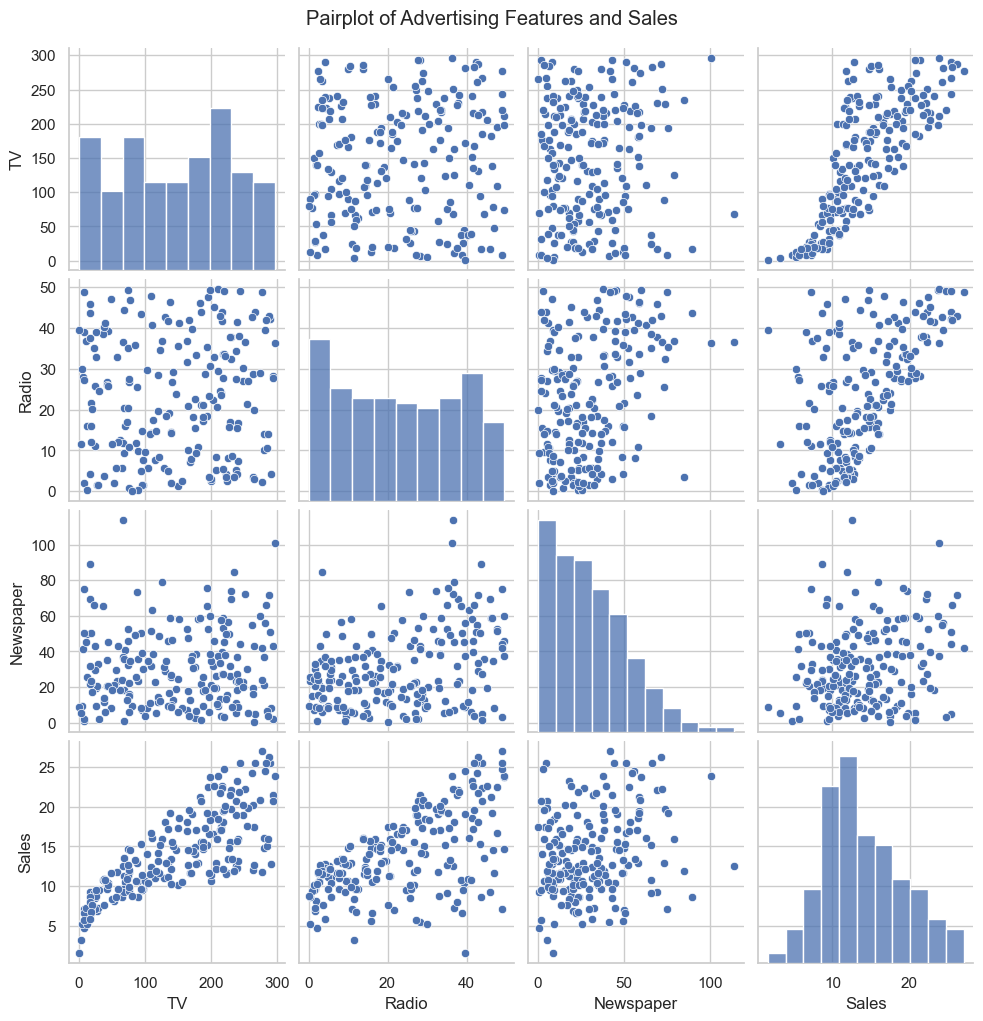

In [21]:
# Visualize relationships between all numerical features
sns.pairplot(df)
plt.suptitle("Pairplot of Advertising Features and Sales", y=1.02)
plt.show()

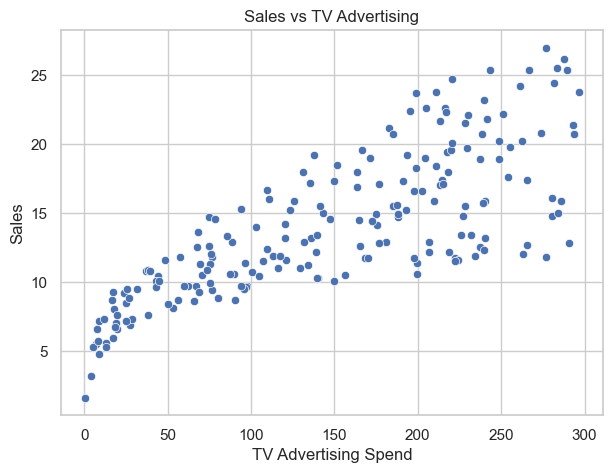

In [23]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="TV", y="Sales")

plt.title("Sales vs TV Advertising")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")
plt.show()

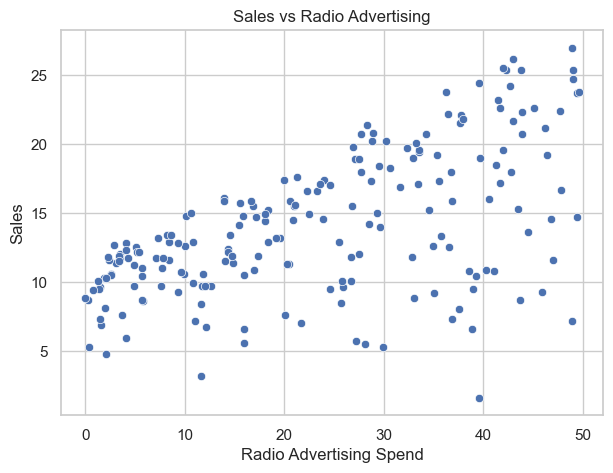

In [25]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Radio", y="Sales")

plt.title("Sales vs Radio Advertising")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")
plt.show()

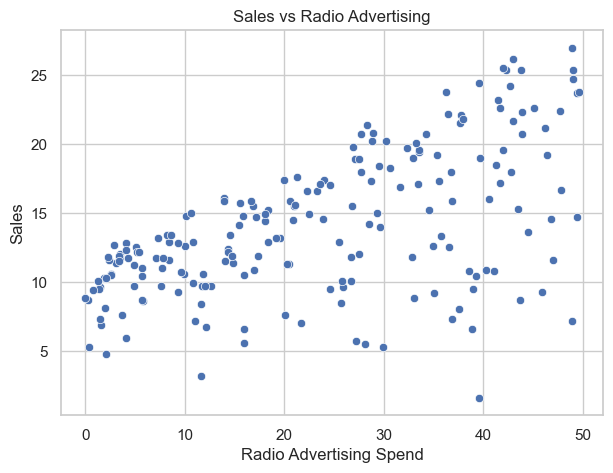

In [27]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Radio", y="Sales")

plt.title("Sales vs Radio Advertising")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")
plt.show()

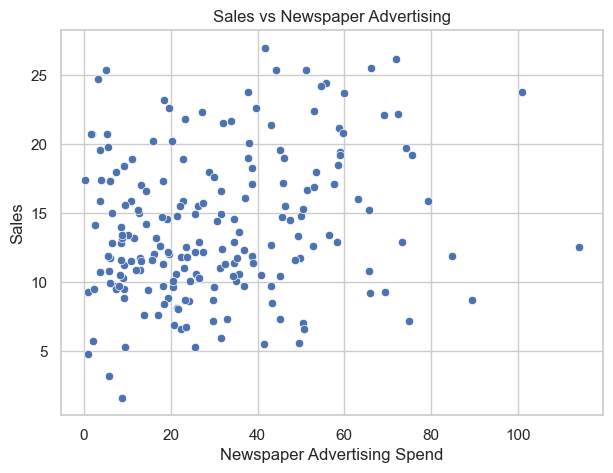

In [29]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Newspaper", y="Sales")

plt.title("Sales vs Newspaper Advertising")
plt.xlabel("Newspaper Advertising Spend")
plt.ylabel("Sales")
plt.show()

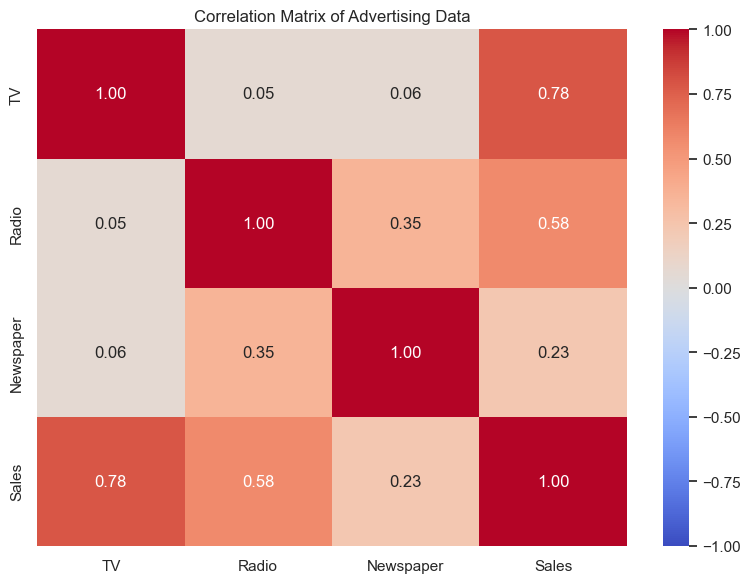

In [33]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Advertising Data")
plt.tight_layout()
plt.show()

The exploratory data analysis compares the relationship between advertising expenditure and sales across TV, Radio, and Newspaper channels. The scatter plots and correlation heatmap help identify which channels show stronger relationships with sales. These relationships will be examined further using regression models.

In [36]:
from sklearn.model_selection import train_test_split

# Input features: advertising expenditure
X = df[["TV", "Radio", "Newspaper"]]

# Target: sales to be predicted
y = df["Sales"]

# Split into training data (80%) and testing data (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 160
Testing samples: 40


In [38]:
from sklearn.linear_model import LinearRegression

# Create and train the baseline model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict sales on test data
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [42]:
from sklearn.ensemble import RandomForestRegressor

# Create and train the second model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict sales on test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Function to calculate metrics for each model
def evaluate_model(y_true, predictions, model_name):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    r2 = r2_score(y_true, predictions)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

# Compare the models
results = pd.DataFrame([
    evaluate_model(y_test, lr_predictions, "Linear Regression"),
    evaluate_model(y_test, rf_predictions, "Random Forest")
])

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.461,1.782,0.899
1,Random Forest,0.620,0.769,0.981


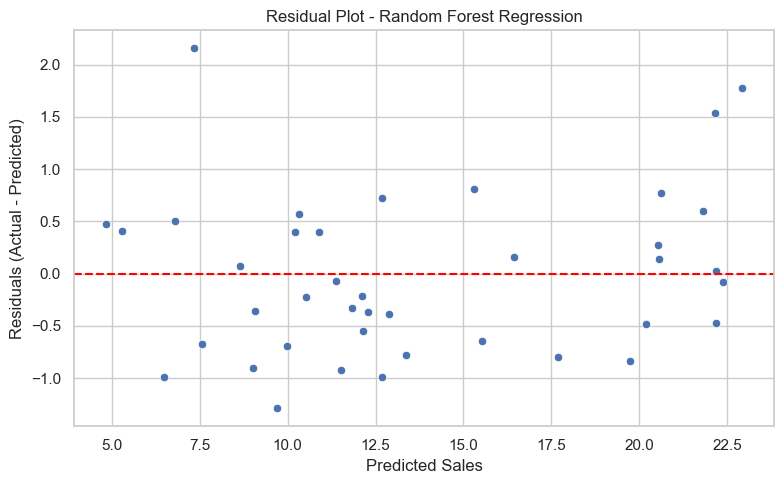

In [46]:
# Calculate residuals for the Random Forest model
residuals = y_test - rf_predictions

# Plot predicted sales against residuals
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rf_predictions,
    y=residuals
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot - Random Forest Regression")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals (Actual - Predicted)")
plt.tight_layout()
plt.show()

,Advertising Channel,Coefficient
1,Radio,0.189
0,TV,0.045
2,Newspaper,0.003


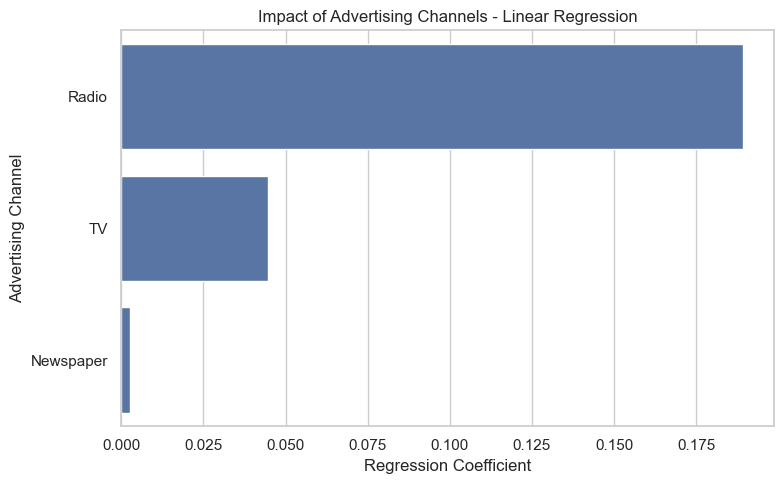

In [48]:
# Display Linear Regression coefficients
coefficients = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Coefficient": lr_model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

display(coefficients.round(3))

# Plot Linear Regression coefficients
plt.figure(figsize=(8, 5))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Advertising Channel"
)

plt.title("Impact of Advertising Channels - Linear Regression")
plt.xlabel("Regression Coefficient")
plt.ylabel("Advertising Channel")
plt.tight_layout()
plt.show()

,Advertising Channel,Importance
0,TV,0.625
1,Radio,0.362
2,Newspaper,0.013


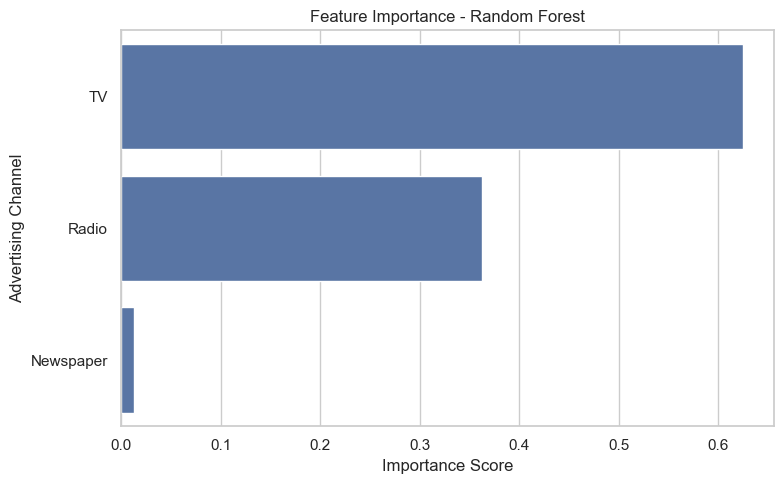

In [50]:
importance = pd.DataFrame({
    "Advertising Channel": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.round(3))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Advertising Channel"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Advertising Channel")
plt.tight_layout()
plt.show()


## Conclusion

This project developed machine learning regression models to predict product sales using advertising expenditure across TV, Radio, and Newspaper channels.

Exploratory data analysis included descriptive statistics, pairplots, individual scatter plots, and a correlation heatmap. Linear Regression was used as the baseline model, and Random Forest Regression was trained as an additional model.

On the test dataset, Linear Regression achieved an MAE of 1.461, RMSE of 1.782, and R² score of 0.899. Random Forest achieved an MAE of 0.620, RMSE of 0.769, and R² score of 0.981. Therefore, Random Forest performed better on this test split.

Residual analysis was used to examine the Random Forest model's prediction errors. Feature importance and regression coefficients were analyzed to compare the influence of the three advertising channels. The channel with the highest importance in the Random Forest model was **[insert the channel identified by your results]**.

Overall, this project demonstrates how regression models can be used to predict sales and analyze the relationship between advertising expenditure and sales.